In [1]:
import sys
import torch

print("Python:", sys.version)
print("Ejecutable:", sys.executable)

print("\nPyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("CUDA de PyTorch:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Ejecutable: c:\Python\python.exe

PyTorch: 2.14.0+cu130
CUDA disponible: True
CUDA de PyTorch: 13.0
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.0 GB


In [2]:
import os
import random
import copy
import json

from pathlib import Path

import numpy as np
import pandas as pd

import cv2

from PIL import Image, ImageEnhance

import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import datasets, models

from torchvision.models import (
    EfficientNet_V2_S_Weights,
    ConvNeXt_Tiny_Weights,
    Swin_T_Weights
)

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Imports cargados correctamente.")

Imports cargados correctamente.


In [ ]:
# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

SEED = 42

BATCH_SIZE = 8
NUM_WORKERS = 0

NUM_CLASSES = 4

CLASS_NAMES = [
    "Blackspot",
    "Canker",
    "Fresh",
    "Greening"
]

# ============================================================
# PRUEBA RÁPIDA
# ============================================================

# True:
#   Fase 1 = 1 época
#   Fase 2 = 1 época
#
# False:
#   Fase 1 = 5 épocas
#   Fase 2 = 25 épocas

TEST_RUN = False

PHASE1_EPOCHS = 1 if TEST_RUN else 5
PHASE2_EPOCHS = 1 if TEST_RUN else 25

# ============================================================
# ENTRENAMIENTO
# ============================================================

LEARNING_RATE_PHASE1 = 0.001
LEARNING_RATE_PHASE2 = 0.00001

WEIGHT_DECAY = 0.0001

EARLY_STOPPING_PATIENCE = 5

# ============================================================
# MODELOS
# ============================================================

MODEL_NAMES = [
    "efficientnet_v2_s",
    "convnext_tiny",
    "swin_tiny"
]


In [35]:
# ============================================================
# SEMILLAS
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.0 GB


In [36]:
# ============================================================
# DATASETS
# ============================================================

KUMAR_DIR = Path("orange_diseases")

KUMAR_TRAIN_DIR = KUMAR_DIR / "train"
KUMAR_TEST_DIR = KUMAR_DIR / "test"

HASSAM_DIR = Path("Fruits")

# ============================================================
# OUTPUTS
# ============================================================

OUTPUT_DIR = Path("outputs")

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
HISTORY_DIR = OUTPUT_DIR / "history"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"

for folder in [
    OUTPUT_DIR,
    CHECKPOINT_DIR,
    HISTORY_DIR,
    RESULTS_DIR,
    FIGURE_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Kumar train:", KUMAR_TRAIN_DIR)
print("Kumar test :", KUMAR_TEST_DIR)
print("Hassam     :", HASSAM_DIR)

Kumar train: orange_diseases\train
Kumar test : orange_diseases\test
Hassam     : Fruits


In [6]:
print(
    "Kumar train existe:",
    KUMAR_TRAIN_DIR.exists()
)

print(
    "Kumar test existe:",
    KUMAR_TEST_DIR.exists()
)

print(
    "Hassam Fruits existe:",
    HASSAM_DIR.exists()
)

Kumar train existe: True
Kumar test existe: True
Hassam Fruits existe: True


In [7]:
# ============================================================
# KUMAR TRAIN
# ============================================================

kumar_train_base = datasets.ImageFolder(
    root=KUMAR_TRAIN_DIR
)

# ============================================================
# KUMAR TEST
# ============================================================

kumar_test_base = datasets.ImageFolder(
    root=KUMAR_TEST_DIR
)

print(
    "Clases Kumar:",
    kumar_train_base.class_to_idx
)

print(
    "Imágenes train originales:",
    len(kumar_train_base)
)

print(
    "Imágenes test originales:",
    len(kumar_test_base)
)

Clases Kumar: {'blackspot': 0, 'canker': 1, 'fresh': 2, 'greening': 3}
Imágenes train originales: 991
Imágenes test originales: 99


In [8]:
# ============================================================
# DIVISIÓN TRAIN / VALIDATION
# ============================================================

all_indices = np.arange(
    len(kumar_train_base)
)

all_targets = np.array(
    kumar_train_base.targets
)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=all_targets
)

print(
    "Entrenamiento:",
    len(train_indices)
)

print(
    "Validación:",
    len(val_indices)
)

print(
    "Test:",
    len(kumar_test_base)
)

Entrenamiento: 842
Validación: 149
Test: 99


In [9]:
def class_distribution(
    targets,
    indices,
    class_to_idx
):

    inverse_map = {
        value: key
        for key, value in class_to_idx.items()
    }

    counts = {
        class_name: 0
        for class_name in CLASS_NAMES
    }

    for idx in indices:

        label = targets[idx]

        original_class = inverse_map[label]

        display_class = original_class.capitalize()

        if original_class == "blackspot":
            display_class = "Blackspot"

        elif original_class == "canker":
            display_class = "Canker"

        elif original_class == "fresh":
            display_class = "Fresh"

        elif original_class == "greening":
            display_class = "Greening"

        counts[display_class] += 1

    return counts


train_distribution = class_distribution(
    all_targets,
    train_indices,
    kumar_train_base.class_to_idx
)

val_distribution = class_distribution(
    all_targets,
    val_indices,
    kumar_train_base.class_to_idx
)

print("Train:")
print(train_distribution)

print("\nValidation:")
print(val_distribution)

Train:
{'Blackspot': 156, 'Canker': 152, 'Fresh': 239, 'Greening': 295}

Validation:
{'Blackspot': 28, 'Canker': 27, 'Fresh': 42, 'Greening': 52}


In [10]:
AUGMENTATION_NAMES = [
    "Reducción de sombras",
    "Ajuste de intensidad",
    "Mejora de brillo",
    "Mejora de contraste local"
]


def apply_augmentation(
    image,
    augmentation_id
):
    """
    Aplica una de las cuatro transformaciones:

    0 -> reducción de sombras
    1 -> ajuste de intensidad
    2 -> mejora de brillo
    3 -> mejora de contraste local
    """

    if not isinstance(image, Image.Image):
        image = Image.fromarray(image)

    image = image.convert("RGB")

    # ========================================================
    # 0. REDUCCIÓN DE SOMBRAS
    # ========================================================

    if augmentation_id == 0:

        image_np = np.array(
            image
        )

        lab = cv2.cvtColor(
            image_np,
            cv2.COLOR_RGB2LAB
        )

        L = lab[:, :, 0]

        kernel = np.ones(
            (21, 21),
            dtype=np.uint8
        )

        background = cv2.morphologyEx(
            L,
            cv2.MORPH_CLOSE,
            kernel
        )

        L_corrected = cv2.divide(
            L,
            background,
            scale=255
        )

        lab[:, :, 0] = L_corrected

        result = cv2.cvtColor(
            lab,
            cv2.COLOR_LAB2RGB
        )

        return Image.fromarray(result)

    # ========================================================
    # 1. AJUSTE DE INTENSIDAD
    # ========================================================

    elif augmentation_id == 1:

        image_np = np.array(
            image
        ).astype(
            np.float32
        )

        image_np = image_np * 1.10

        image_np = np.clip(
            image_np,
            0,
            255
        ).astype(
            np.uint8
        )

        return Image.fromarray(
            image_np
        )

    # ========================================================
    # 2. MEJORA DE BRILLO
    # ========================================================

    elif augmentation_id == 2:

        enhancer = ImageEnhance.Brightness(
            image
        )

        return enhancer.enhance(
            1.20
        )

    # ========================================================
    # 3. MEJORA DE CONTRASTE LOCAL
    # ========================================================

    elif augmentation_id == 3:

        image_np = np.array(
            image
        )

        lab = cv2.cvtColor(
            image_np,
            cv2.COLOR_RGB2LAB
        )

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        lab[:, :, 0] = clahe.apply(
            lab[:, :, 0]
        )

        result = cv2.cvtColor(
            lab,
            cv2.COLOR_LAB2RGB
        )

        return Image.fromarray(
            result
        )

    else:

        raise ValueError(
            f"augmentation_id inválido: "
            f"{augmentation_id}"
        )

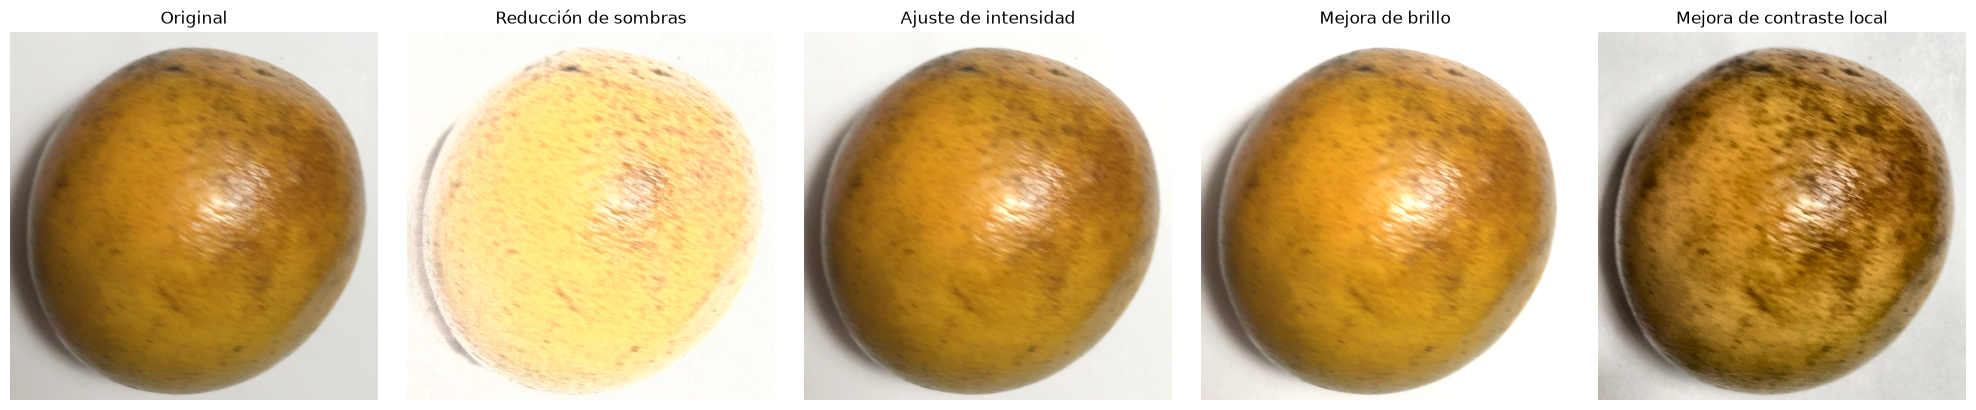

In [11]:
image_path, label = (
    kumar_train_base.samples[0]
)

original_image = Image.open(
    image_path
).convert("RGB")

fig, axes = plt.subplots(
    1,
    5,
    figsize=(20, 4)
)

# Imagen original
axes[0].imshow(
    original_image
)

axes[0].set_title(
    "Original"
)

axes[0].axis("off")

# Cuatro augmentations
for i in range(4):

    augmented_image = apply_augmentation(
        original_image,
        i
    )

    axes[i + 1].imshow(
        augmented_image
    )

    axes[i + 1].set_title(
        AUGMENTATION_NAMES[i]
    )

    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class AugmentedKumarDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        indices,
        transform,
        num_augmentations=4
    ):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform
        self.num_augmentations = num_augmentations

    def __len__(self):

        return (
            len(self.indices)
            * self.num_augmentations
        )

    def __getitem__(
        self,
        idx
    ):

        base_position = (
            idx
            // self.num_augmentations
        )

        augmentation_id = (
            idx
            % self.num_augmentations
        )

        original_index = (
            self.indices[base_position]
        )

        image_path, label = (
            self.base_dataset.samples[
                original_index
            ]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        image = apply_augmentation(
            image,
            augmentation_id
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

In [ ]:
class KumarSubsetDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        indices,
        transform
    ):

        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        
        return len(self.indices)

    def __getitem__(
        self,
        idx
    ):

        original_index = (
            self.indices[idx]
        )

        image_path, label = (
            self.base_dataset.samples[
                original_index
            ]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

In [14]:
HASSAM_CLASS_MAP = {
    "black spot": 0,
    "canker": 1,
    "healthy": 2,
    "greening": 3
}


class HassamFruitDataset(Dataset):

    def __init__(
        self,
        root_dir,
        transform=None
    ):

        self.root_dir = Path(
            root_dir
        )

        self.transform = transform

        self.samples = []

        for folder in sorted(
            self.root_dir.iterdir()
        ):

            if not folder.is_dir():
                continue

            folder_name = (
                folder.name
                .lower()
                .strip()
            )

            # Ignorar Scab
            if folder_name not in HASSAM_CLASS_MAP:
                continue

            label = HASSAM_CLASS_MAP[
                folder_name
            ]

            for image_path in sorted(
                folder.iterdir()
            ):

                if image_path.suffix.lower() in [
                    ".jpg",
                    ".jpeg",
                    ".png",
                    ".bmp",
                    ".webp"
                ]:

                    self.samples.append(
                        (
                            image_path,
                            label
                        )
                    )

    def __len__(self):

        return len(
            self.samples
        )

    def __getitem__(
        self,
        idx
    ):

        image_path, label = (
            self.samples[idx]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

In [15]:
print("Carpetas de Hassam:")

for folder in sorted(
    HASSAM_DIR.iterdir()
):

    if folder.is_dir():

        print(
            "-",
            folder.name
        )

Carpetas de Hassam:
- Black spot
- Canker
- Greening
- healthy
- Scab


In [16]:
hassam_check = HassamFruitDataset(
    HASSAM_DIR
)

print(
    "\nImágenes Hassam utilizadas:",
    len(hassam_check)
)

hassam_counts = {
    class_name: 0
    for class_name in CLASS_NAMES
}

for _, label in hassam_check.samples:

    hassam_counts[
        CLASS_NAMES[label]
    ] += 1

print("\nDistribución:")
for class_name, count in hassam_counts.items():

    print(
        f"{class_name}: {count}"
    )


Imágenes Hassam utilizadas: 135

Distribución:
Blackspot: 19
Canker: 78
Fresh: 22
Greening: 16


In [17]:
def build_model(
    model_name
):

    # ========================================================
    # EFFICIENTNETV2-S
    # ========================================================

    if model_name == "efficientnet_v2_s":

        weights = (
            EfficientNet_V2_S_Weights
            .IMAGENET1K_V1
        )

        model = models.efficientnet_v2_s(
            weights=weights
        )

        in_features = (
            model.classifier[1]
            .in_features
        )

        model.classifier[1] = nn.Linear(
            in_features,
            NUM_CLASSES
        )

        return model, weights

    # ========================================================
    # CONVNEXT-TINY
    # ========================================================

    elif model_name == "convnext_tiny":

        weights = (
            ConvNeXt_Tiny_Weights
            .IMAGENET1K_V1
        )

        model = models.convnext_tiny(
            weights=weights
        )

        in_features = (
            model.classifier[2]
            .in_features
        )

        model.classifier[2] = nn.Linear(
            in_features,
            NUM_CLASSES
        )

        return model, weights

    # ========================================================
    # SWIN-TINY
    # ========================================================

    elif model_name == "swin_tiny":

        weights = (
            Swin_T_Weights
            .IMAGENET1K_V1
        )

        model = models.swin_t(
            weights=weights
        )

        in_features = (
            model.head
            .in_features
        )

        model.head = nn.Linear(
            in_features,
            NUM_CLASSES
        )

        return model, weights

    else:

        raise ValueError(
            f"Modelo no reconocido: "
            f"{model_name}"
        )

In [18]:
def freeze_backbone(
    model,
    model_name
):

    # Congelar todo
    for param in model.parameters():

        param.requires_grad = False

    # Descongelar clasificador
    if model_name == "efficientnet_v2_s":

        for param in (
            model.classifier.parameters()
        ):

            param.requires_grad = True

    elif model_name == "convnext_tiny":

        for param in (
            model.classifier.parameters()
        ):

            param.requires_grad = True

    elif model_name == "swin_tiny":

        for param in (
            model.head.parameters()
        ):

            param.requires_grad = True


def unfreeze_all(model):

    for param in model.parameters():

        param.requires_grad = True

In [19]:
def create_dataloaders(
    model_name
):

    # Obtener pesos y transformaciones
    _, weights = build_model(
        model_name
    )

    transform = weights.transforms()

    # ========================================================
    # KUMAR TRAIN + AUGMENTATION
    # ========================================================

    train_dataset = AugmentedKumarDataset(
        base_dataset=kumar_train_base,
        indices=train_indices,
        transform=transform,
        num_augmentations=4
    )

    # ========================================================
    # KUMAR VALIDATION
    # ========================================================

    val_dataset = KumarSubsetDataset(
        base_dataset=kumar_train_base,
        indices=val_indices,
        transform=transform
    )

    # ========================================================
    # KUMAR TEST
    # ========================================================

    kumar_test_dataset = datasets.ImageFolder(
        root=KUMAR_TEST_DIR,
        transform=transform
    )

    # ========================================================
    # HASSAM EXTERNO
    # ========================================================

    hassam_dataset = HassamFruitDataset(
        root_dir=HASSAM_DIR,
        transform=transform
    )

    # ========================================================
    # DATALOADERS
    # ========================================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    kumar_test_loader = DataLoader(
        kumar_test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    hassam_loader = DataLoader(
        hassam_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    return (
        train_loader,
        val_loader,
        kumar_test_loader,
        hassam_loader
    )

In [20]:
(
    train_loader,
    val_loader,
    kumar_test_loader,
    hassam_loader
) = create_dataloaders(
    "convnext_tiny"
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Kumar test batches:",
    len(kumar_test_loader)
)

print(
    "Hassam batches:",
    len(hassam_loader)
)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\User/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:03<00:00, 33.6MB/s] 


Train batches: 421
Validation batches: 19
Kumar test batches: 13
Hassam batches: 17


In [21]:
images, labels = next(
    iter(train_loader)
)

print(
    "Shape imágenes:",
    images.shape
)

print(
    "Shape etiquetas:",
    labels.shape
)

print(
    "Device antes de mover:",
    images.device
)

Shape imágenes: torch.Size([8, 3, 224, 224])
Shape etiquetas: torch.Size([8])
Device antes de mover: cpu


In [22]:
def evaluate_model(
    model,
    dataloader
):

    model.eval()

    all_targets = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )

            predictions = outputs.argmax(
                dim=1
            )

            all_targets.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    precision = precision_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        all_targets,
        all_predictions,
        labels=list(
            range(NUM_CLASSES)
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_macro": f1_macro,
        "targets": all_targets,
        "predictions": all_predictions,
        "confusion_matrix": cm
    }

In [23]:
def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for images, labels in dataloader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = images.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

    return (
        running_loss
        / total_samples
    )

In [ ]:
def train_model(
    model_name,
    train_loader,
    val_loader
):

    print("\n")
    print("=" * 70)
    print(
        f"ENTRENANDO: {model_name}"
    )
    print("=" * 70)

    # ========================================================
    # CREAR MODELO
    # ========================================================

    model, _ = build_model(
        model_name
    )

    model = model.to(
        DEVICE
    )

    criterion = nn.CrossEntropyLoss()

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"best_{model_name}.pth"
    )

    history = []

    best_macro_f1 = -np.inf

    best_state_dict = None

    # ========================================================
    # FASE 1
    # ========================================================

    print(
        "\nFASE 1 - Extracción de características"
    )

    freeze_backbone(
        model,
        model_name
    )

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=LEARNING_RATE_PHASE1,
        weight_decay=WEIGHT_DECAY
    )

    patience_counter = 0

    for epoch in range(
        1,
        PHASE1_EPOCHS + 1
    ):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_metrics = evaluate_model(
            model,
            val_loader
        )

        val_f1 = val_metrics[
            "f1_macro"
        ]

        history.append({
            "phase": "feature_extraction",
            "epoch": epoch,
            "train_loss": train_loss,
            "val_accuracy":
                val_metrics["accuracy"],
            "val_precision":
                val_metrics["precision"],
            "val_recall":
                val_metrics["recall"],
            "val_f1_macro":
                val_f1
        })

        print(
            f"Época {epoch}/{PHASE1_EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )

        # ----------------------------------------------------
        # MEJOR MODELO
        # ----------------------------------------------------

        if val_f1 > best_macro_f1:

            best_macro_f1 = val_f1

            best_state_dict = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

            print(
                "  ✓ Nuevo mejor checkpoint"
            )

        else:

            patience_counter += 1

            if (
                patience_counter
                >= EARLY_STOPPING_PATIENCE
            ):

                print(
                    "  Early stopping fase 1"
                )

                break

    # Recuperar mejor estado
    if best_state_dict is not None:

        model.load_state_dict(
            best_state_dict
        )

    # ========================================================
    # FASE 2
    # ========================================================

    print(
        "\nFASE 2 - Fine-tuning"
    )

    unfreeze_all(
        model
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE_PHASE2,
        weight_decay=WEIGHT_DECAY
    )

    patience_counter = 0

    for epoch in range(
        1,
        PHASE2_EPOCHS + 1
    ):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_metrics = evaluate_model(
            model,
            val_loader
        )

        val_f1 = val_metrics[
            "f1_macro"
        ]

        history.append({
            "phase": "fine_tuning",
            "epoch": epoch,
            "train_loss": train_loss,
            "val_accuracy":
                val_metrics["accuracy"],
            "val_precision":
                val_metrics["precision"],
            "val_recall":
                val_metrics["recall"],
            "val_f1_macro":
                val_f1
        })

        print(
            f"Época {epoch}/{PHASE2_EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )

        if val_f1 > best_macro_f1:

            best_macro_f1 = val_f1

            best_state_dict = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

            print(
                "  ✓ Nuevo mejor checkpoint"
            )

        else:

            patience_counter += 1

            if (
                patience_counter
                >= EARLY_STOPPING_PATIENCE
            ):

                print(
                    "  Early stopping fase 2"
                )

                break

    # ========================================================
    # CARGAR MEJOR ESTADO
    # ========================================================

    model.load_state_dict(
        best_state_dict
    )

    # ========================================================
    # GUARDAR CHECKPOINT
    # ========================================================

    torch.save(
        {
            "model_name": model_name,
            "num_classes": NUM_CLASSES,
            "class_names": CLASS_NAMES,
            "best_macro_f1": best_macro_f1,
            "state_dict": best_state_dict
        },
        checkpoint_path
    )

    print(
        "\n✓ Pesos guardados:"
    )

    print(
        checkpoint_path
    )

    # ========================================================
    # GUARDAR HISTORIAL
    # ========================================================

    history_df = pd.DataFrame(
        history
    )

    history_path = (
        HISTORY_DIR
        / f"history_{model_name}.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print(
        "✓ Historial guardado:"
    )

    print(
        history_path
    )

    return (
        model,
        checkpoint_path,
        history_df
    )

In [25]:
def save_confusion_matrix(
    cm,
    model_name,
    dataset_name
):

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    im = ax.imshow(
        cm
    )

    ax.set_xticks(
        range(NUM_CLASSES)
    )

    ax.set_yticks(
        range(NUM_CLASSES)
    )

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        CLASS_NAMES
    )

    ax.set_xlabel(
        "Predicción"
    )

    ax.set_ylabel(
        "Real"
    )

    ax.set_title(
        f"Matriz de confusión - "
        f"{model_name} - "
        f"{dataset_name}"
    )

    for i in range(NUM_CLASSES):

        for j in range(NUM_CLASSES):

            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax
    )

    plt.tight_layout()

    output_path = (
        FIGURE_DIR
        / f"confusion_"
        f"{model_name}_"
        f"{dataset_name}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    return output_path

In [26]:
def load_best_model(
    model_name,
    checkpoint_path
):

    model, _ = build_model(
        model_name
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    model.load_state_dict(
        checkpoint["state_dict"]
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return model



################################################################################
MODELO: efficientnet_v2_s
################################################################################
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\User/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:02<00:00, 31.5MB/s]




ENTRENANDO: efficientnet_v2_s

FASE 1 - Extracción de características
Época 1/5 | Loss: 0.3862 | Val Macro F1: 0.9635
  ✓ Nuevo mejor checkpoint
Época 2/5 | Loss: 0.1868 | Val Macro F1: 0.9818
  ✓ Nuevo mejor checkpoint
Época 3/5 | Loss: 0.1455 | Val Macro F1: 0.9909
  ✓ Nuevo mejor checkpoint
Época 4/5 | Loss: 0.1294 | Val Macro F1: 0.9818
Época 5/5 | Loss: 0.1216 | Val Macro F1: 0.9909

FASE 2 - Fine-tuning
Época 1/25 | Loss: 0.0987 | Val Macro F1: 1.0000
  ✓ Nuevo mejor checkpoint
Época 2/25 | Loss: 0.0447 | Val Macro F1: 1.0000
Época 3/25 | Loss: 0.0288 | Val Macro F1: 1.0000
Época 4/25 | Loss: 0.0200 | Val Macro F1: 1.0000
Época 5/25 | Loss: 0.0179 | Val Macro F1: 1.0000
Época 6/25 | Loss: 0.0104 | Val Macro F1: 0.9909
  Early stopping fase 2

✓ Pesos guardados:
outputs\checkpoints\best_efficientnet_v2_s.pth
✓ Historial guardado:
outputs\history\history_efficientnet_v2_s.csv


EVALUACIÓN INTERNA - KUMAR TEST
Accuracy : 0.9596
Precision: 0.9545
Recall   : 0.9545
F1 Macro : 0.9545

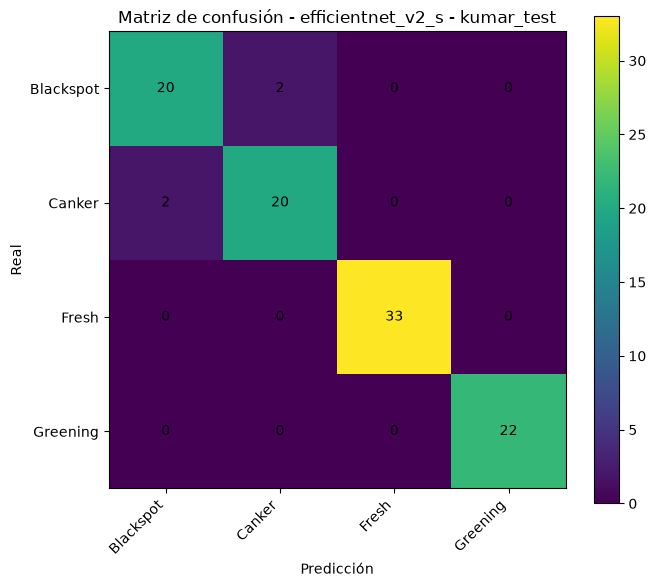



EVALUACIÓN EXTERNA - HASSAM FRUITS
Accuracy : 0.2519
Precision: 0.1754
Recall   : 0.2640
F1 Macro : 0.1461


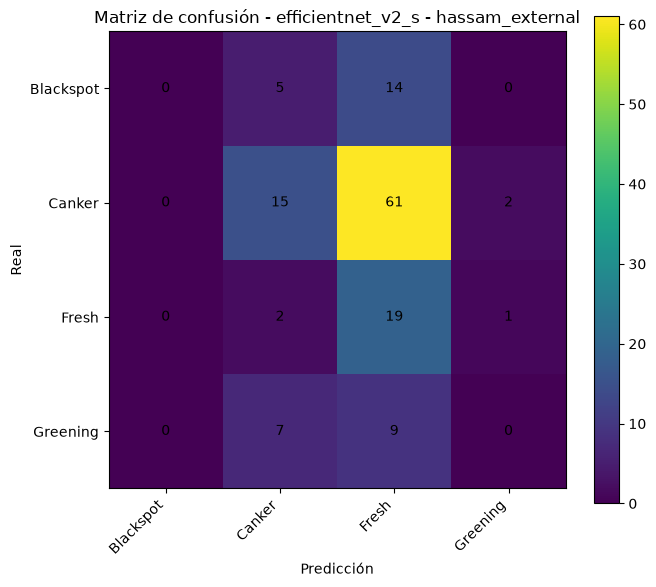



################################################################################
MODELO: convnext_tiny
################################################################################


ENTRENANDO: convnext_tiny

FASE 1 - Extracción de características
Época 1/5 | Loss: 0.1987 | Val Macro F1: 0.9765
  ✓ Nuevo mejor checkpoint
Época 2/5 | Loss: 0.0608 | Val Macro F1: 0.9818
  ✓ Nuevo mejor checkpoint
Época 3/5 | Loss: 0.0436 | Val Macro F1: 0.9909
  ✓ Nuevo mejor checkpoint
Época 4/5 | Loss: 0.0392 | Val Macro F1: 1.0000
  ✓ Nuevo mejor checkpoint
Época 5/5 | Loss: 0.0308 | Val Macro F1: 0.9909

FASE 2 - Fine-tuning
Época 1/25 | Loss: 0.0263 | Val Macro F1: 1.0000
Época 2/25 | Loss: 0.0071 | Val Macro F1: 1.0000
Época 3/25 | Loss: 0.0069 | Val Macro F1: 0.9818
Época 4/25 | Loss: 0.0021 | Val Macro F1: 1.0000
Época 5/25 | Loss: 0.0038 | Val Macro F1: 0.9909
  Early stopping fase 2

✓ Pesos guardados:
outputs\checkpoints\best_convnext_tiny.pth
✓ Historial guardado:
outputs\history\histor

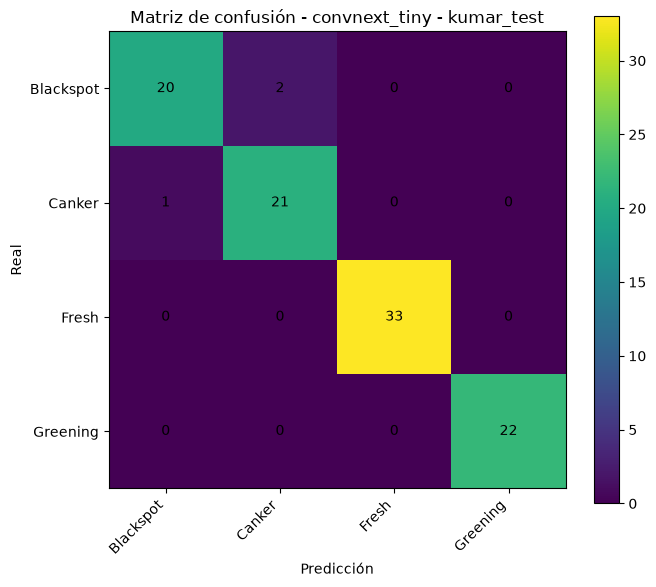



EVALUACIÓN EXTERNA - HASSAM FRUITS
Accuracy : 0.3481
Precision: 0.3432
Recall   : 0.3323
F1 Macro : 0.2575


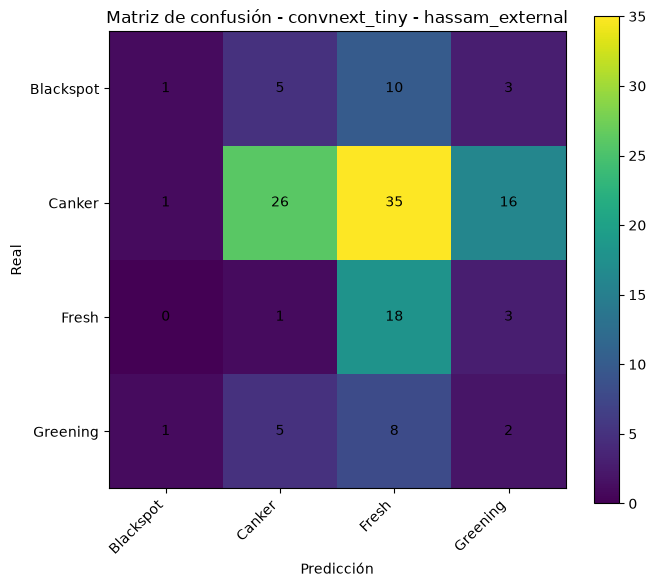



################################################################################
MODELO: swin_tiny
################################################################################
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to C:\Users\User/.cache\torch\hub\checkpoints\swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:03<00:00, 34.0MB/s] 




ENTRENANDO: swin_tiny

FASE 1 - Extracción de características
Época 1/5 | Loss: 0.2903 | Val Macro F1: 1.0000
  ✓ Nuevo mejor checkpoint
Época 2/5 | Loss: 0.1055 | Val Macro F1: 1.0000
Época 3/5 | Loss: 0.0739 | Val Macro F1: 1.0000
Época 4/5 | Loss: 0.0630 | Val Macro F1: 1.0000
Época 5/5 | Loss: 0.0558 | Val Macro F1: 1.0000

FASE 2 - Fine-tuning
Época 1/25 | Loss: 0.0423 | Val Macro F1: 0.9909
Época 2/25 | Loss: 0.0195 | Val Macro F1: 0.9635
Época 3/25 | Loss: 0.0096 | Val Macro F1: 0.9727
Época 4/25 | Loss: 0.0037 | Val Macro F1: 1.0000
Época 5/25 | Loss: 0.0025 | Val Macro F1: 1.0000
  Early stopping fase 2

✓ Pesos guardados:
outputs\checkpoints\best_swin_tiny.pth
✓ Historial guardado:
outputs\history\history_swin_tiny.csv


EVALUACIÓN INTERNA - KUMAR TEST
Accuracy : 0.9495
Precision: 0.9436
Recall   : 0.9432
F1 Macro : 0.9432


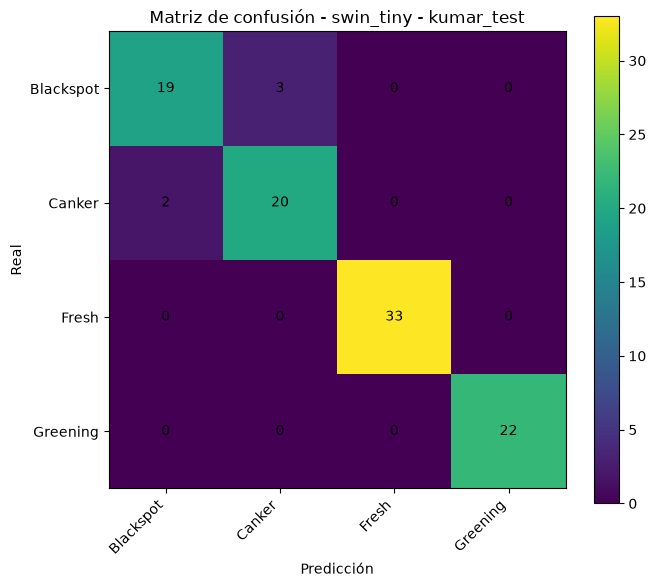



EVALUACIÓN EXTERNA - HASSAM FRUITS
Accuracy : 0.3926
Precision: 0.3777
Recall   : 0.4065
F1 Macro : 0.3115


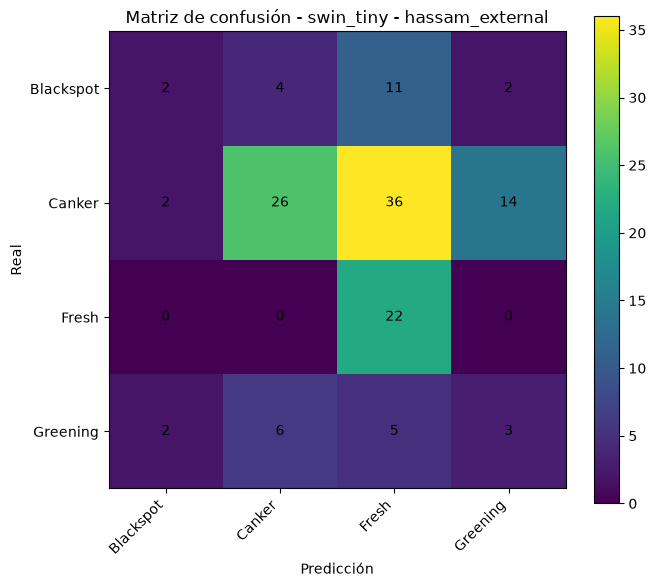

In [37]:
results = []

for model_name in MODEL_NAMES:

    print("\n")
    print("#" * 80)
    print(
        f"MODELO: {model_name}"
    )
    print("#" * 80)

    # ========================================================
    # DATALOADERS
    # ========================================================

    (
        train_loader,
        val_loader,
        kumar_test_loader,
        hassam_loader
    ) = create_dataloaders(
        model_name
    )

    # ========================================================
    # ENTRENAMIENTO
    # ========================================================

    model, checkpoint_path, history_df = (
        train_model(
            model_name=model_name,
            train_loader=train_loader,
            val_loader=val_loader
        )
    )

    # ========================================================
    # RECARGAR CHECKPOINT
    # ========================================================

    # Esto garantiza que las evaluaciones utilicen
    # exactamente los pesos guardados.

    del model

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    model = load_best_model(
        model_name,
        checkpoint_path
    )

    # ========================================================
    # TEST KUMAR
    # ========================================================

    print("\n")
    print(
        "EVALUACIÓN INTERNA - KUMAR TEST"
    )

    kumar_metrics = evaluate_model(
        model,
        kumar_test_loader
    )

    print(
        f"Accuracy : "
        f"{kumar_metrics['accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{kumar_metrics['precision']:.4f}"
    )

    print(
        f"Recall   : "
        f"{kumar_metrics['recall']:.4f}"
    )

    print(
        f"F1 Macro : "
        f"{kumar_metrics['f1_macro']:.4f}"
    )

    save_confusion_matrix(
        kumar_metrics[
            "confusion_matrix"
        ],
        model_name,
        "kumar_test"
    )

    results.append({

        "modelo":
            model_name,

        "dataset":
            "Kumar_Test",

        "accuracy":
            kumar_metrics[
                "accuracy"
            ],

        "precision":
            kumar_metrics[
                "precision"
            ],

        "recall":
            kumar_metrics[
                "recall"
            ],

        "f1_macro":
            kumar_metrics[
                "f1_macro"
            ]
    })

    # ========================================================
    # HASSAM EXTERNO
    # ========================================================

    print("\n")
    print(
        "EVALUACIÓN EXTERNA - HASSAM FRUITS"
    )

    hassam_metrics = evaluate_model(
        model,
        hassam_loader
    )

    print(
        f"Accuracy : "
        f"{hassam_metrics['accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{hassam_metrics['precision']:.4f}"
    )

    print(
        f"Recall   : "
        f"{hassam_metrics['recall']:.4f}"
    )

    print(
        f"F1 Macro : "
        f"{hassam_metrics['f1_macro']:.4f}"
    )

    save_confusion_matrix(
        hassam_metrics[
            "confusion_matrix"
        ],
        model_name,
        "hassam_external"
    )

    results.append({

        "modelo":
            model_name,

        "dataset":
            "Hassam_External",

        "accuracy":
            hassam_metrics[
                "accuracy"
            ],

        "precision":
            hassam_metrics[
                "precision"
            ],

        "recall":
            hassam_metrics[
                "recall"
            ],

        "f1_macro":
            hassam_metrics[
                "f1_macro"
            ]
    })

    # Liberar memoria
    del model

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

In [43]:
# ============================================================
# EVALUACIÓN POSTERIOR DE MODELOS YA ENTRENADOS
# SIN REENTRENAMIENTO
# ============================================================

evaluation_results = []

for model_name in [
    "efficientnet_v2_s",
    "convnext_tiny",
    "swin_tiny"
]:

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"best_{model_name}.pth"
    )

    print("\n" + "=" * 70)
    print(f"EVALUANDO: {model_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Crear DataLoaders
    # --------------------------------------------------------

    (
        _,
        _,
        kumar_test_loader,
        hassam_loader
    ) = create_dataloaders(
        model_name
    )

    # --------------------------------------------------------
    # Cargar mejores pesos
    # --------------------------------------------------------

    model = load_best_model(
        model_name,
        checkpoint_path
    )

    # ========================================================
    # KUMAR TEST
    # ========================================================

    print("\n--- Kumar Test ---")

    kumar_metrics = evaluate_model(
        model,
        kumar_test_loader
    )

    print(
        f"Accuracy : {kumar_metrics['accuracy']:.4f}"
    )
    print(
        f"Precision: {kumar_metrics['precision']:.4f}"
    )
    print(
        f"Recall   : {kumar_metrics['recall']:.4f}"
    )
    print(
        f"F1 Macro : {kumar_metrics['f1_macro']:.4f}"
    )

    print("\nClassification Report - Kumar")

    print(
        classification_report(
            kumar_metrics["targets"],
            kumar_metrics["predictions"],
            labels=[0, 1, 2, 3],
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # ========================================================
    # HASSAM
    # ========================================================

    print("\n--- Hassam External ---")

    hassam_metrics = evaluate_model(
        model,
        hassam_loader
    )

    print(
        f"Accuracy : {hassam_metrics['accuracy']:.4f}"
    )
    print(
        f"Precision: {hassam_metrics['precision']:.4f}"
    )
    print(
        f"Recall   : {hassam_metrics['recall']:.4f}"
    )
    print(
        f"F1 Macro : {hassam_metrics['f1_macro']:.4f}"
    )

    print("\nClassification Report - Hassam")

    print(
        classification_report(
            hassam_metrics["targets"],
            hassam_metrics["predictions"],
            labels=[0, 1, 2, 3],
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # ========================================================
    # GUARDAR RESULTADOS
    # ========================================================

    evaluation_results.append({
        "modelo": model_name,
        "dataset": "Kumar_Test",
        "accuracy": kumar_metrics["accuracy"],
        "precision": kumar_metrics["precision"],
        "recall": kumar_metrics["recall"],
        "f1_macro": kumar_metrics["f1_macro"]
    })

    evaluation_results.append({
        "modelo": model_name,
        "dataset": "Hassam_External",
        "accuracy": hassam_metrics["accuracy"],
        "precision": hassam_metrics["precision"],
        "recall": hassam_metrics["recall"],
        "f1_macro": hassam_metrics["f1_macro"]
    })

    # Liberar memoria
    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


EVALUANDO: efficientnet_v2_s

--- Kumar Test ---
Accuracy : 0.9596
Precision: 0.9545
Recall   : 0.9545
F1 Macro : 0.9545

Classification Report - Kumar
              precision    recall  f1-score   support

   Blackspot       0.91      0.91      0.91        22
      Canker       0.91      0.91      0.91        22
       Fresh       1.00      1.00      1.00        33
    Greening       1.00      1.00      1.00        22

    accuracy                           0.96        99
   macro avg       0.95      0.95      0.95        99
weighted avg       0.96      0.96      0.96        99


--- Hassam External ---
Accuracy : 0.2519
Precision: 0.1754
Recall   : 0.2640
F1 Macro : 0.1461

Classification Report - Hassam
              precision    recall  f1-score   support

   Blackspot       0.00      0.00      0.00        19
      Canker       0.52      0.19      0.28        78
       Fresh       0.18      0.86      0.30        22
    Greening       0.00      0.00      0.00        16

    accurac

In [45]:
# ============================================================
# REVISIÓN LIMPIA DE HASSAM - EFFICIENTNETV2-S
# SIN ENTRENAMIENTO
# ============================================================

model_name = "efficientnet_v2_s"

checkpoint_path = (
    CHECKPOINT_DIR
    / f"best_{model_name}.pth"
)

print("Checkpoint:")
print(checkpoint_path)

# Crear DataLoader específico de EfficientNetV2-S
_, _, _, hassam_loader = create_dataloaders(
    model_name
)

# Cargar mejores pesos
model = load_best_model(
    model_name,
    checkpoint_path
)

# Evaluación
hassam_metrics = evaluate_model(
    model,
    hassam_loader
)

print("\n===== HASSAM EXTERNAL =====")

print(
    f"Accuracy : {hassam_metrics['accuracy']:.6f}"
)

print(
    f"Precision: {hassam_metrics['precision']:.6f}"
)

print(
    f"Recall   : {hassam_metrics['recall']:.6f}"
)

print(
    f"F1 Macro : {hassam_metrics['f1_macro']:.6f}"
)

print("\n===== MATRIZ DE CONFUSIÓN =====")

print(
    hassam_metrics["confusion_matrix"]
)

print("\n===== CLASSIFICATION REPORT =====")

report = classification_report(
    hassam_metrics["targets"],
    hassam_metrics["predictions"],
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0
)

print(
    "\nTotal imágenes Hassam:",
    len(hassam_loader.dataset)
)

print(report)

Checkpoint:
outputs\checkpoints\best_efficientnet_v2_s.pth

===== HASSAM EXTERNAL =====
Accuracy : 0.251852
Precision: 0.175427
Recall   : 0.263986
F1 Macro : 0.146093

===== MATRIZ DE CONFUSIÓN =====
[[ 0  5 14  0]
 [ 0 15 61  2]
 [ 0  2 19  1]
 [ 0  7  9  0]]

===== CLASSIFICATION REPORT =====

Total imágenes Hassam: 135
              precision    recall  f1-score   support

   Blackspot       0.00      0.00      0.00        19
      Canker       0.52      0.19      0.28        78
       Fresh       0.18      0.86      0.30        22
    Greening       0.00      0.00      0.00        16

    accuracy                           0.25       135
   macro avg       0.18      0.26      0.15       135
weighted avg       0.33      0.25      0.21       135



In [38]:
results_df = pd.DataFrame(
    results
)

results_path = (
    RESULTS_DIR
    / "results_kumar_hassam.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print(
    "Resultados guardados en:"
)

print(
    results_path
)

results_df

Resultados guardados en:
outputs\results\results_kumar_hassam.csv


,modelo,dataset,accuracy,precision,recall,f1_macro
0,efficientnet_v2_s,Kumar_Test,0.959596,0.954545,0.954545,0.954545
1,efficientnet_v2_s,Hassam_External,0.251852,0.175427,0.263986,0.146093
2,convnext_tiny,Kumar_Test,0.969697,0.966356,0.965909,0.965891
3,convnext_tiny,Hassam_External,0.348148,0.343223,0.332287,0.257545
4,swin_tiny,Kumar_Test,0.949495,0.943582,0.943182,0.943152
5,swin_tiny,Hassam_External,0.392593,0.377687,0.406524,0.311476


In [39]:
comparison_df = results_df.pivot(
    index="modelo",
    columns="dataset",
    values=[
        "accuracy",
        "precision",
        "recall",
        "f1_macro"
    ]
)

comparison_df

accuracy                  precision             \
dataset           Hassam_External Kumar_Test Hassam_External Kumar_Test   
modelo                                                                    
convnext_tiny            0.348148   0.969697        0.343223   0.966356   
efficientnet_v2_s        0.251852   0.959596        0.175427   0.954545   
swin_tiny                0.392593   0.949495        0.377687   0.943582   

                           recall                   f1_macro             
dataset           Hassam_External Kumar_Test Hassam_External Kumar_Test  
modelo                                                                   
convnext_tiny            0.332287   0.965909        0.257545   0.965891  
efficientnet_v2_s        0.263986   0.954545        0.146093   0.954545  
swin_tiny                0.406524   0.943182        0.311476   0.943152

In [40]:
generalization_results = []

for model_name in MODEL_NAMES:

    internal = results_df[
        (results_df["modelo"] == model_name)
        &
        (
            results_df["dataset"]
            == "Kumar_Test"
        )
    ].iloc[0]

    external = results_df[
        (results_df["modelo"] == model_name)
        &
        (
            results_df["dataset"]
            == "Hassam_External"
        )
    ].iloc[0]

    generalization_results.append({

        "modelo":
            model_name,

        "delta_accuracy":
            external["accuracy"]
            - internal["accuracy"],

        "delta_precision":
            external["precision"]
            - internal["precision"],

        "delta_recall":
            external["recall"]
            - internal["recall"],

        "delta_f1_macro":
            external["f1_macro"]
            - internal["f1_macro"]
    })

generalization_df = pd.DataFrame(
    generalization_results
)

generalization_df

,modelo,delta_accuracy,delta_precision,delta_recall,delta_f1_macro
0,efficientnet_v2_s,-0.707744,-0.779119,-0.690559,-0.808452
1,convnext_tiny,-0.621549,-0.623133,-0.633622,-0.708347
2,swin_tiny,-0.556902,-0.565895,-0.536658,-0.631677


In [41]:
final_table = results_df.copy()

final_table["accuracy"] = (
    final_table["accuracy"] * 100
).round(2)

final_table["precision"] = (
    final_table["precision"] * 100
).round(2)

final_table["recall"] = (
    final_table["recall"] * 100
).round(2)

final_table["f1_macro"] = (
    final_table["f1_macro"] * 100
).round(2)

final_table

,modelo,dataset,accuracy,precision,recall,f1_macro
0,efficientnet_v2_s,Kumar_Test,95.96,95.45,95.45,95.45
1,efficientnet_v2_s,Hassam_External,25.19,17.54,26.40,14.61
2,convnext_tiny,Kumar_Test,96.97,96.64,96.59,96.59
3,convnext_tiny,Hassam_External,34.81,34.32,33.23,25.75
4,swin_tiny,Kumar_Test,94.95,94.36,94.32,94.32
5,swin_tiny,Hassam_External,39.26,37.77,40.65,31.15
